In [2]:
df_encoded = pd.get_dummies(
    df,
    columns=["Country"],
    dtype=int
)

In [3]:
df_encoded.head()

,Unnamed: 0,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,MissingCustomer,Transaction_Total,...,Country_RSA,Country_Saudi Arabia,Country_Singapore,Country_Spain,Country_Sweden,Country_Switzerland,Country_USA,Country_United Arab Emirates,Country_United Kingdom,Country_Unspecified
0,0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,False,15.30,...,0,0,0,0,0,0,0,0,1,0
1,1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,False,20.34,...,0,0,0,0,0,0,0,0,1,0
2,2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,False,22.00,...,0,0,0,0,0,0,0,0,1,0
3,3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,False,20.34,...,0,0,0,0,0,0,0,0,1,0
4,4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,False,20.34,...,0,0,0,0,0,0,0,0,1,0


In [4]:
numeric_cols = df_encoded.select_dtypes(include="number").columns.tolist()
numeric_cols

['Unnamed: 0',
 'InvoiceNo',
 'Quantity',
 'UnitPrice',
 'CustomerID',
 'Transaction_Total',
 'Country_Australia',
 'Country_Austria',
 'Country_Bahrain',
 'Country_Belgium',
 'Country_Brazil',
 'Country_Canada',
 'Country_Channel Islands',
 'Country_Cyprus',
 'Country_Czech Republic',
 'Country_Denmark',
 'Country_EIRE',
 'Country_European Community',
 'Country_Finland',
 'Country_France',
 'Country_Germany',
 'Country_Greece',
 'Country_Iceland',
 'Country_Israel',
 'Country_Italy',
 'Country_Japan',
 'Country_Lebanon',
 'Country_Lithuania',
 'Country_Malta',
 'Country_Netherlands',
 'Country_Norway',
 'Country_Poland',
 'Country_Portugal',
 'Country_RSA',
 'Country_Saudi Arabia',
 'Country_Singapore',
 'Country_Spain',
 'Country_Sweden',
 'Country_Switzerland',
 'Country_USA',
 'Country_United Arab Emirates',
 'Country_United Kingdom',
 'Country_Unspecified']

In [5]:
numeric_cols.remove('CustomerID')
numeric_cols.remove('Unnamed: 0')
numeric_cols.remove('InvoiceNo')

In [6]:
customer_df = (
    df_encoded
    .groupby("CustomerID")[numeric_cols]
    .sum()
    .reset_index()
)

In [7]:
customer_df

,CustomerID,Quantity,UnitPrice,Transaction_Total,Country_Australia,Country_Austria,Country_Bahrain,Country_Belgium,Country_Brazil,Country_Canada,...,Country_RSA,Country_Saudi Arabia,Country_Singapore,Country_Spain,Country_Sweden,Country_Switzerland,Country_USA,Country_United Arab Emirates,Country_United Kingdom,Country_Unspecified
0,12346.0,74215,1.04,77183.60,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,12347.0,2458,481.21,4310.00,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,12348.0,2341,178.71,1797.24,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,12349.0,631,605.10,1757.55,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,12350.0,197,65.30,334.40,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4333,18280.0,45,47.65,180.60,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,10,0
4334,18281.0,54,39.36,80.82,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,7,0
4335,18282.0,103,62.39,178.05,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,12,0
4336,18283.0,1357,1174.33,2045.53,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,721,0


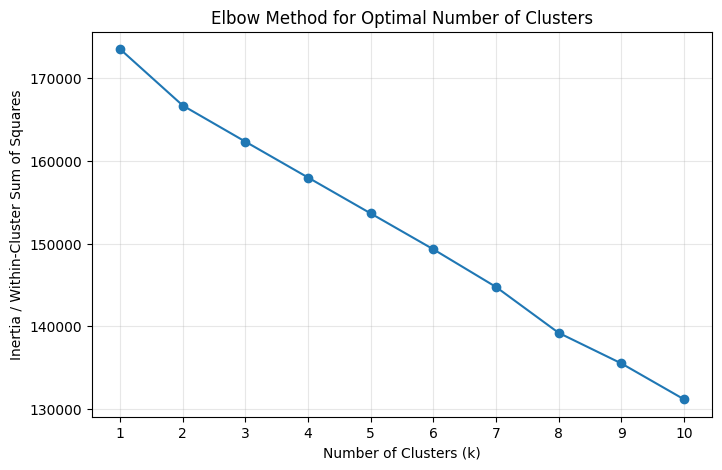

In [8]:
inertia = []
k_values = range(1, 11)
results = []
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

X = customer_df.drop(columns="CustomerID")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    labels = kmeans.fit_predict(X_scaled)
    if k >= 2:
        score = silhouette_score(X_scaled, labels)

        results.append({
            "k": k,
            "silhouette_score": score
        })
    inertia.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [9]:
results

[{'k': 2, 'silhouette_score': 0.9658618465060481},
 {'k': 3, 'silhouette_score': 0.958239649872683},
 {'k': 4, 'silhouette_score': 0.9582680504319568},
 {'k': 5, 'silhouette_score': 0.958422111992742},
 {'k': 6, 'silhouette_score': 0.9585765230730904},
 {'k': 7, 'silhouette_score': 0.9587318999624963},
 {'k': 8, 'silhouette_score': 0.9448335835850497},
 {'k': 9, 'silhouette_score': 0.9207778048284452},
 {'k': 10, 'silhouette_score': 0.9212317804810484}]

In [10]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

X = customer_df.drop(columns="CustomerID")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init="auto"
)

customer_df["cluster"] = kmeans.fit_predict(X_scaled)

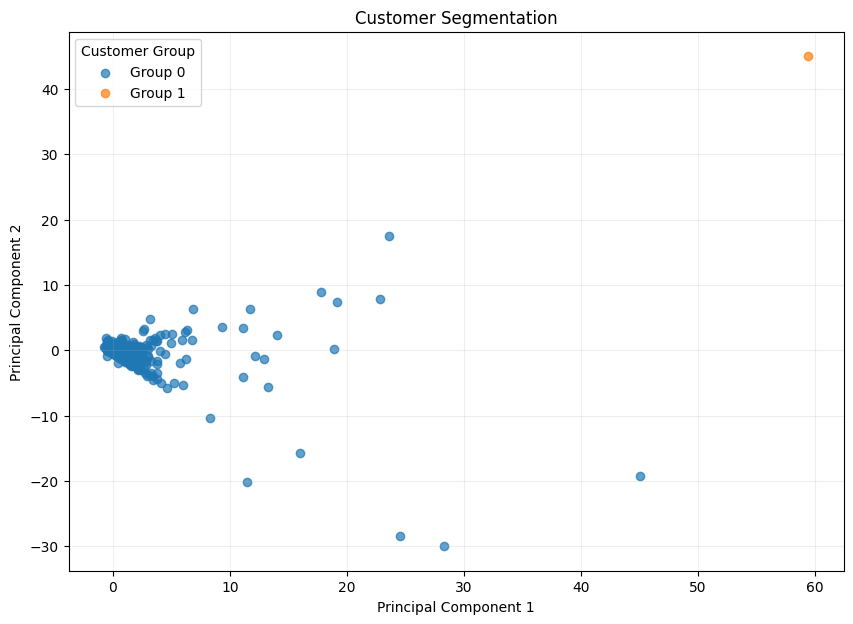

In [11]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

customer_df["PC1"] = X_pca[:, 0]
customer_df["PC2"] = X_pca[:, 1]



plt.figure(figsize=(10, 7))

for cluster in sorted(customer_df["cluster"].unique()):
    subset = customer_df[
        customer_df["cluster"] == cluster
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Group {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation")
plt.legend(title="Customer Group")
plt.grid(alpha=0.2)

plt.show()

In [12]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_df = (
    df.groupby("CustomerID")
      .agg(
          monetary=("Transaction_Total", "sum"),
          frequency=("InvoiceNo", "nunique"),
          total_quantity=("Quantity", "sum"),
          unique_products=("StockCode", "nunique"),
          last_purchase=("InvoiceDate", "max")
      )
      .reset_index()
)

customer_df.head()

,CustomerID,monetary,frequency,total_quantity,unique_products,last_purchase
0,12346.0,77183.60,1,74215,1,2011-01-18 10:01:00
1,12347.0,4310.00,7,2458,103,2011-12-07 15:52:00
2,12348.0,1797.24,4,2341,22,2011-09-25 13:13:00
3,12349.0,1757.55,1,631,73,2011-11-21 09:51:00
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00


In [13]:
customer_df['avg_purchase_val'] = customer_df['monetary'] / customer_df['frequency']
customer_df

,CustomerID,monetary,frequency,total_quantity,unique_products,last_purchase,avg_purchase_val
0,12346.0,77183.60,1,74215,1,2011-01-18 10:01:00,77183.600000
1,12347.0,4310.00,7,2458,103,2011-12-07 15:52:00,615.714286
2,12348.0,1797.24,4,2341,22,2011-09-25 13:13:00,449.310000
3,12349.0,1757.55,1,631,73,2011-11-21 09:51:00,1757.550000
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00,334.400000
...,...,...,...,...,...,...,...
4333,18280.0,180.60,1,45,10,2011-03-07 09:52:00,180.600000
4334,18281.0,80.82,1,54,7,2011-06-12 10:53:00,80.820000
4335,18282.0,178.05,2,103,12,2011-12-02 11:43:00,89.025000
4336,18283.0,2045.53,16,1357,263,2011-12-06 12:02:00,127.845625


In [14]:
customer_df['recency'] = (reference_date - customer_df['last_purchase']).dt.days
customer_df

,CustomerID,monetary,frequency,total_quantity,unique_products,last_purchase,avg_purchase_val,recency
0,12346.0,77183.60,1,74215,1,2011-01-18 10:01:00,77183.600000,326
1,12347.0,4310.00,7,2458,103,2011-12-07 15:52:00,615.714286,2
2,12348.0,1797.24,4,2341,22,2011-09-25 13:13:00,449.310000,75
3,12349.0,1757.55,1,631,73,2011-11-21 09:51:00,1757.550000,19
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00,334.400000,310
...,...,...,...,...,...,...,...,...
4333,18280.0,180.60,1,45,10,2011-03-07 09:52:00,180.600000,278
4334,18281.0,80.82,1,54,7,2011-06-12 10:53:00,80.820000,181
4335,18282.0,178.05,2,103,12,2011-12-02 11:43:00,89.025000,8
4336,18283.0,2045.53,16,1357,263,2011-12-06 12:02:00,127.845625,4


In [15]:
customer_df = customer_df.drop(columns=["last_purchase"])

In [16]:
customer_df.describe()

,CustomerID,monetary,frequency,total_quantity,unique_products,avg_purchase_val,recency
count,4338.000000,4338.000000,4338.000000,4338.000000,4338.000000,4338.000000,4338.000000
mean,15300.408022,2048.688081,4.272015,1187.644537,61.501153,417.645735,92.536422
std,1721.808492,8985.230220,7.697998,5043.619654,85.366768,1796.511343,100.014169
min,12346.000000,3.750000,1.000000,1.000000,1.000000,3.450000,1.000000
25%,13813.250000,306.482500,1.000000,159.000000,16.000000,177.867083,18.000000
50%,15299.500000,668.570000,2.000000,378.000000,35.000000,291.940000,51.000000
75%,16778.750000,1660.597500,5.000000,989.750000,77.000000,428.280625,142.000000
max,18287.000000,280206.020000,209.000000,196915.000000,1787.000000,84236.250000,374.000000


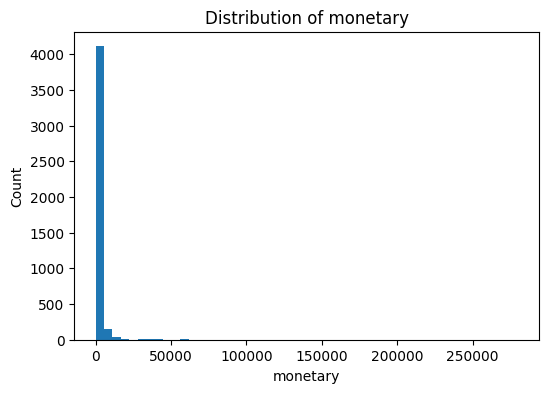

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.hist(customer_df['monetary'], bins=50)
plt.title(f"Distribution of monetary")
plt.xlabel('monetary')
plt.ylabel("Count")
plt.show()

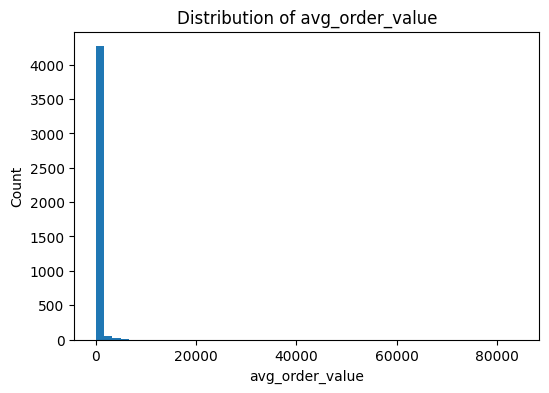

In [18]:
plt.figure(figsize=(6, 4))
plt.hist(customer_df['avg_purchase_val'], bins=50)
plt.title(f"Distribution of avg_order_value")
plt.xlabel('avg_order_value')
plt.ylabel("Count")
plt.show()

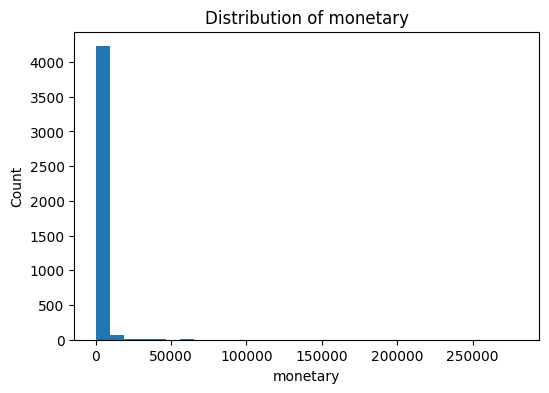

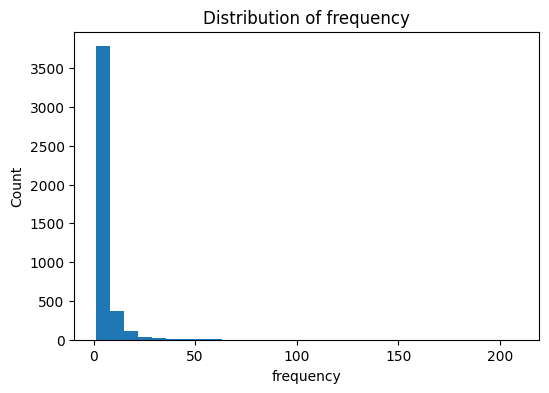

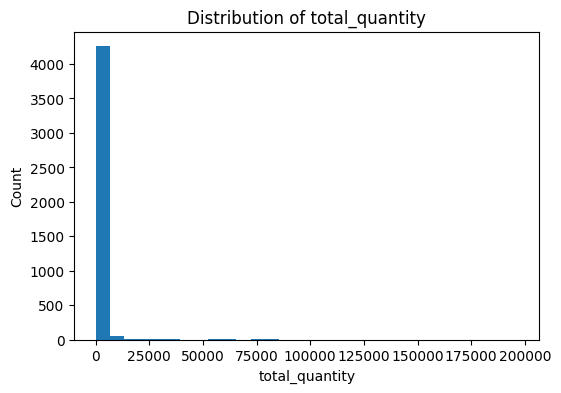

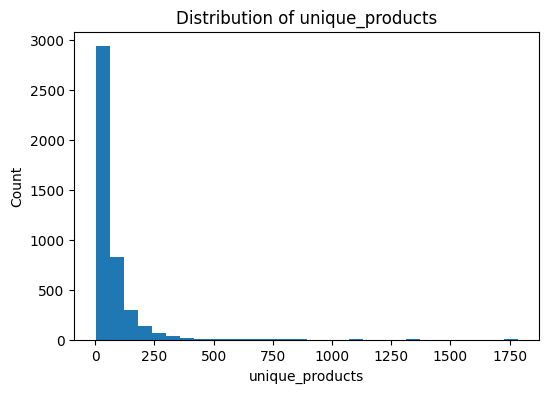

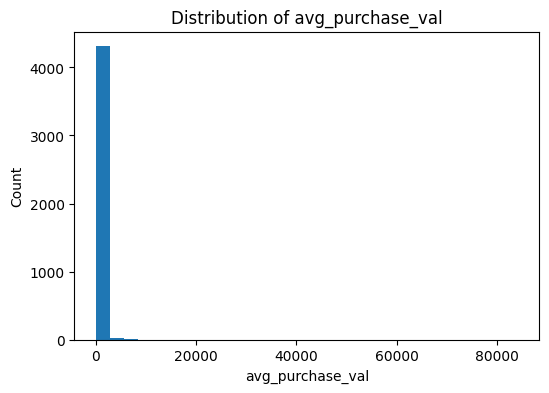

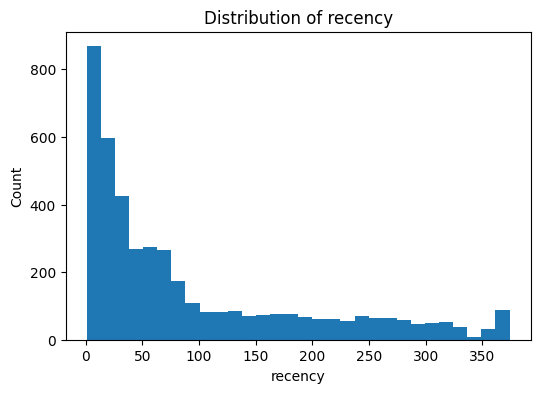

In [19]:
import matplotlib.pyplot as plt

features = [
    "monetary",
    "frequency",
    "total_quantity",
    "unique_products",
    "avg_purchase_val",
    'recency'
]

for col in features:
    plt.figure(figsize=(6, 4))
    plt.hist(customer_df[col], bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

In [20]:
import numpy as np
features = [
    "monetary",
    "frequency",
    "total_quantity",
    "unique_products",
    "avg_purchase_val"]


for col in features:
    customer_df[f"log_{col}"] = np.log1p(customer_df[col])

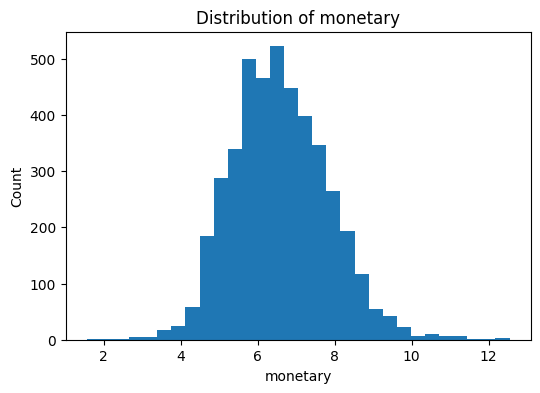

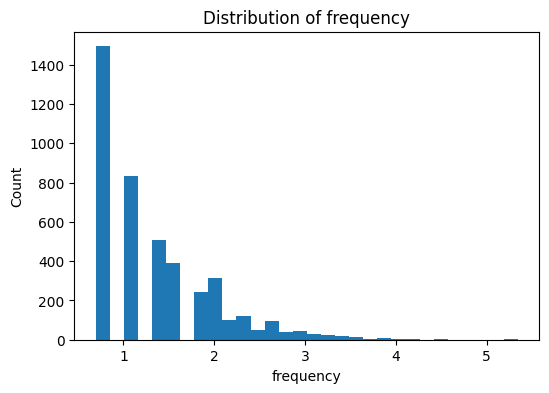

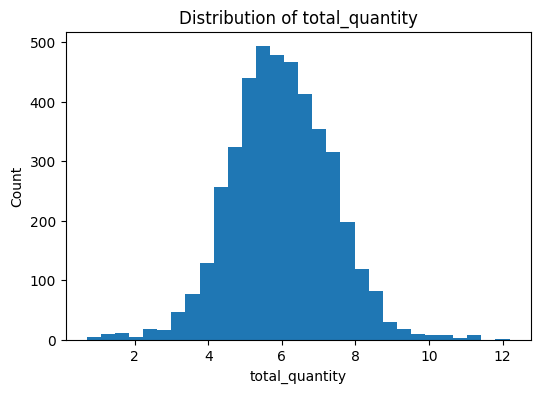

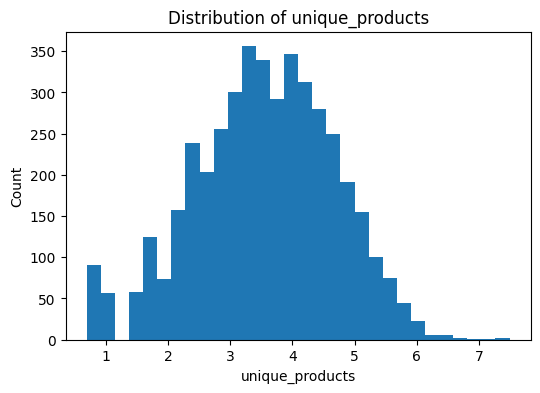

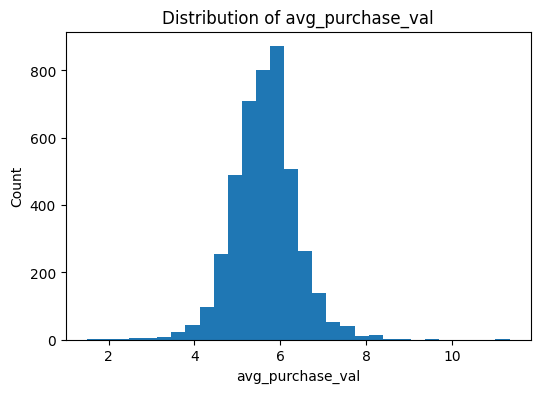

In [21]:
for col in features:
    plt.figure(figsize=(6, 4))
    plt.hist(customer_df[f"log_{col}"], bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

In [22]:
customer_df

,CustomerID,monetary,frequency,total_quantity,unique_products,avg_purchase_val,recency,log_monetary,log_frequency,log_total_quantity,log_unique_products,log_avg_purchase_val
0,12346.0,77183.60,1,74215,1,77183.600000,326,11.253955,0.693147,11.214735,0.693147,11.253955
1,12347.0,4310.00,7,2458,103,615.714286,2,8.368925,2.079442,7.807510,4.644391,6.424406
2,12348.0,1797.24,4,2341,22,449.310000,75,7.494564,1.609438,7.758761,3.135494,6.109936
3,12349.0,1757.55,1,631,73,1757.550000,19,7.472245,0.693147,6.448889,4.304065,7.472245
4,12350.0,334.40,1,197,17,334.400000,310,5.815324,0.693147,5.288267,2.890372,5.815324
...,...,...,...,...,...,...,...,...,...,...,...,...
4333,18280.0,180.60,1,45,10,180.600000,278,5.201806,0.693147,3.828641,2.397895,5.201806
4334,18281.0,80.82,1,54,7,80.820000,181,4.404522,0.693147,4.007333,2.079442,4.404522
4335,18282.0,178.05,2,103,12,89.025000,8,5.187665,1.098612,4.644391,2.564949,4.500087
4336,18283.0,2045.53,16,1357,263,127.845625,4,7.623901,2.833213,7.213768,5.575949,4.858615


In [23]:
from sklearn.preprocessing import StandardScaler

model_features = [
    "log_monetary",
    "log_frequency",
    "log_total_quantity",
    "log_unique_products",
    "log_avg_purchase_val",
    "recency"
]
scaler = StandardScaler()
X = customer_df[model_features]
X_scaled = scaler.fit_transform(X)
# X_scaled = customer_df[model_features]

X_scaled.shape

(4338, 6)

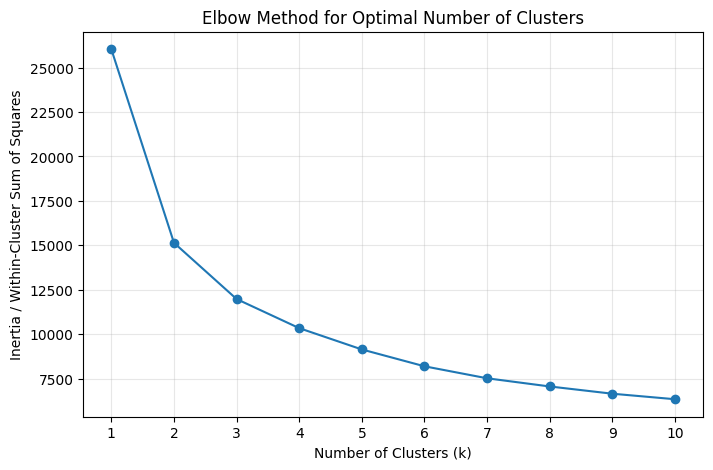

In [24]:
inertia = []
k_values = range(1, 11)
results = []
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score


for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    labels = kmeans.fit_predict(X_scaled)
    if k >= 2:
        score = silhouette_score(X_scaled, labels)

        results.append({
            "k": k,
            "silhouette_score": score
        })
    inertia.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [25]:
results

[{'k': 2, 'silhouette_score': 0.35087972449004934},
 {'k': 3, 'silhouette_score': 0.27233856936839324},
 {'k': 4, 'silhouette_score': 0.27399238588005786},
 {'k': 5, 'silhouette_score': 0.24079500780616786},
 {'k': 6, 'silhouette_score': 0.24415073069456075},
 {'k': 7, 'silhouette_score': 0.23076296777819227},
 {'k': 8, 'silhouette_score': 0.22364332616920457},
 {'k': 9, 'silhouette_score': 0.21659909598091084},
 {'k': 10, 'silhouette_score': 0.21664041376811313}]

In [26]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init="auto"
)

customer_df["cluster"] = kmeans.fit_predict(X_scaled)

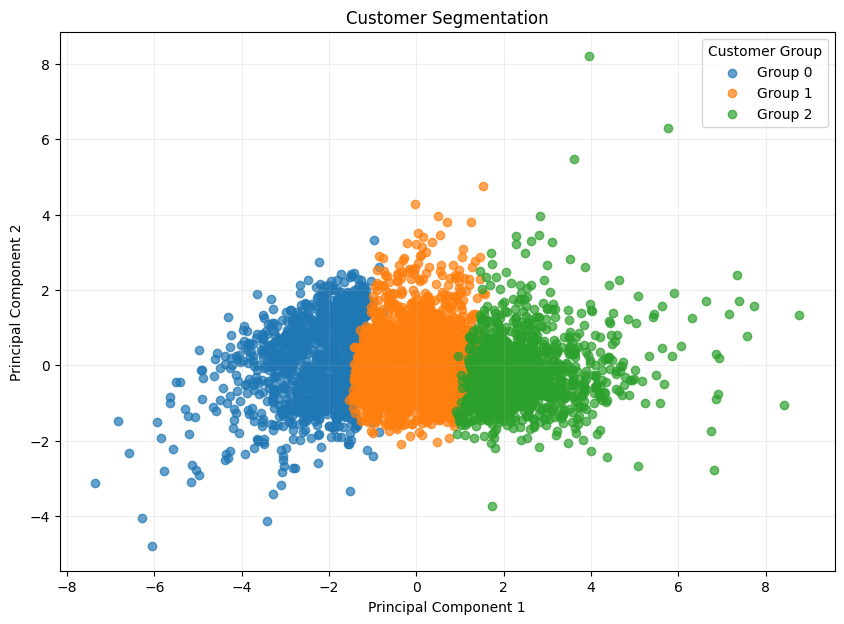

In [27]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

customer_df["PC1"] = X_pca[:, 0]
customer_df["PC2"] = X_pca[:, 1]



plt.figure(figsize=(10, 7))

for cluster in sorted(customer_df["cluster"].unique()):
    subset = customer_df[
        customer_df["cluster"] == cluster
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Group {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation")
plt.legend(title="Customer Group")
plt.grid(alpha=0.2)

plt.show()

In [28]:
customer_df[model_features].corr()

,log_monetary,log_frequency,log_total_quantity,log_unique_products,log_avg_purchase_val,recency
log_monetary,1.000000,0.808119,0.921667,0.692399,0.708863,-0.434169
log_frequency,0.808119,1.000000,0.752504,0.622730,0.164300,-0.472760
log_total_quantity,0.921667,0.752504,1.000000,0.701705,0.642217,-0.452703
log_unique_products,0.692399,0.622730,0.701705,1.000000,0.403010,-0.418400
log_avg_purchase_val,0.708863,0.164300,0.642217,0.403010,1.000000,-0.138638
recency,-0.434169,-0.472760,-0.452703,-0.418400,-0.138638,1.000000


In [29]:
from sklearn.preprocessing import StandardScaler

model_features = [
    "log_frequency",
    "log_unique_products",
    "log_avg_purchase_val",
    "recency"
]
scaler = StandardScaler()
X = customer_df[model_features]
X_scaled = scaler.fit_transform(X)
# X_scaled = customer_df[model_features]

X_scaled.shape

(4338, 4)

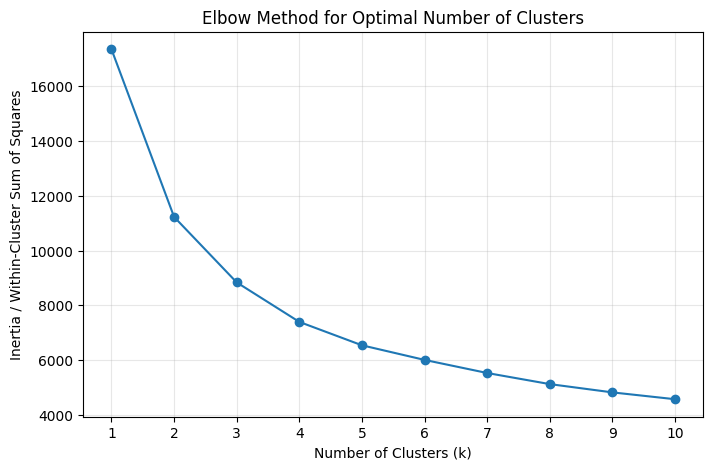

In [30]:
inertia = []
k_values = range(1, 11)
results = []
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score


for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    labels = kmeans.fit_predict(X_scaled)
    if k >= 2:
        score = silhouette_score(X_scaled, labels)

        results.append({
            "k": k,
            "silhouette_score": score
        })
    inertia.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

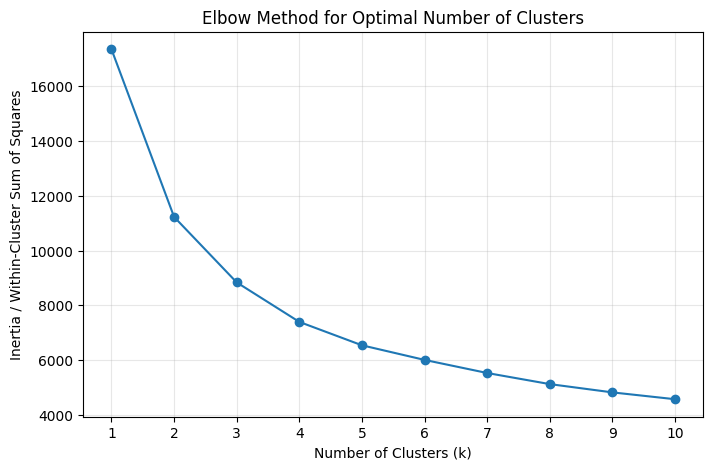

In [31]:
inertia = []
k_values = range(1, 11)
results = []
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score


for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    labels = kmeans.fit_predict(X_scaled)
    if k >= 2:
        score = silhouette_score(X_scaled, labels)

        results.append({
            "k": k,
            "silhouette_score": score
        })
    inertia.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [32]:
results

[{'k': 2, 'silhouette_score': 0.31015871895355135},
 {'k': 3, 'silhouette_score': 0.2850039810724538},
 {'k': 4, 'silhouette_score': 0.26314985212400066},
 {'k': 5, 'silhouette_score': 0.24428434650781977},
 {'k': 6, 'silhouette_score': 0.2358414087524427},
 {'k': 7, 'silhouette_score': 0.23321248819291643},
 {'k': 8, 'silhouette_score': 0.21596791292438206},
 {'k': 9, 'silhouette_score': 0.21186066804534134},
 {'k': 10, 'silhouette_score': 0.21797955505066394}]

In [33]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init="auto"
)

customer_df["cluster"] = kmeans.fit_predict(X_scaled)

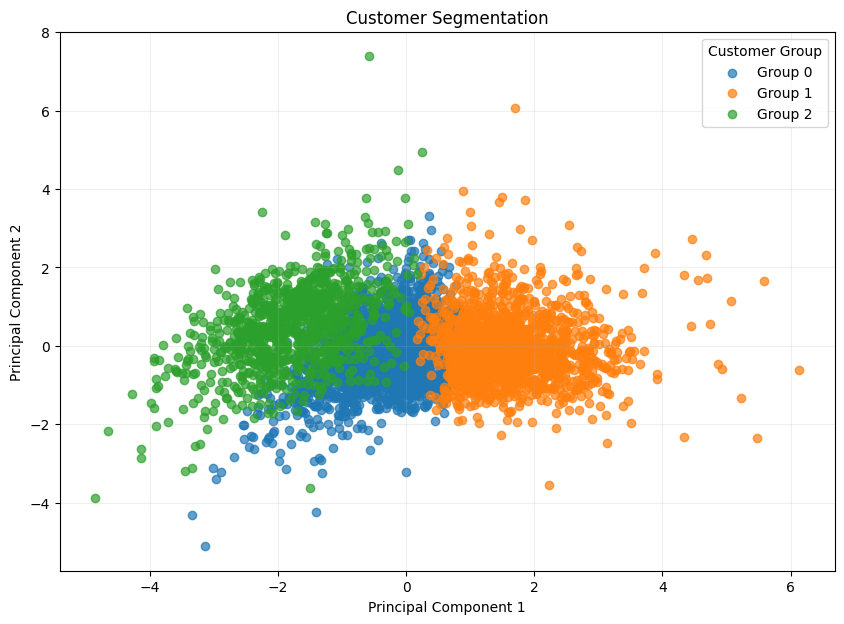

In [34]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

customer_df["PC1"] = X_pca[:, 0]
customer_df["PC2"] = X_pca[:, 1]



plt.figure(figsize=(10, 7))

for cluster in sorted(customer_df["cluster"].unique()):
    subset = customer_df[
        customer_df["cluster"] == cluster
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Group {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation")
plt.legend(title="Customer Group")
plt.grid(alpha=0.2)

plt.show()

## RFM Baseline

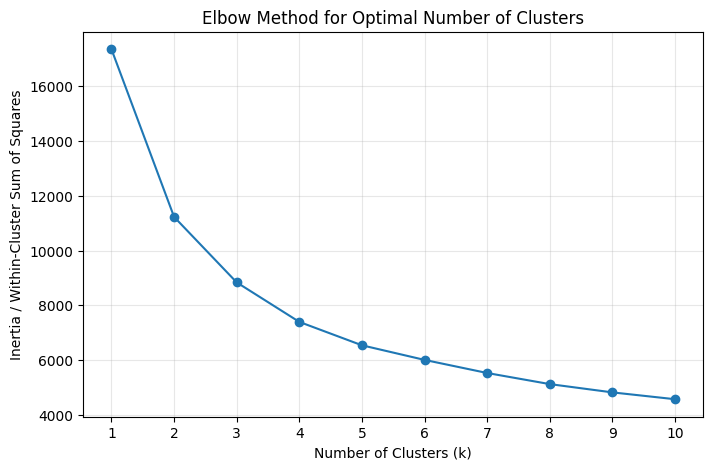

In [35]:
inertia = []
k_values = range(1, 11)
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [36]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init="auto"
)

customer_df["cluster"] = kmeans.fit_predict(X_scaled)

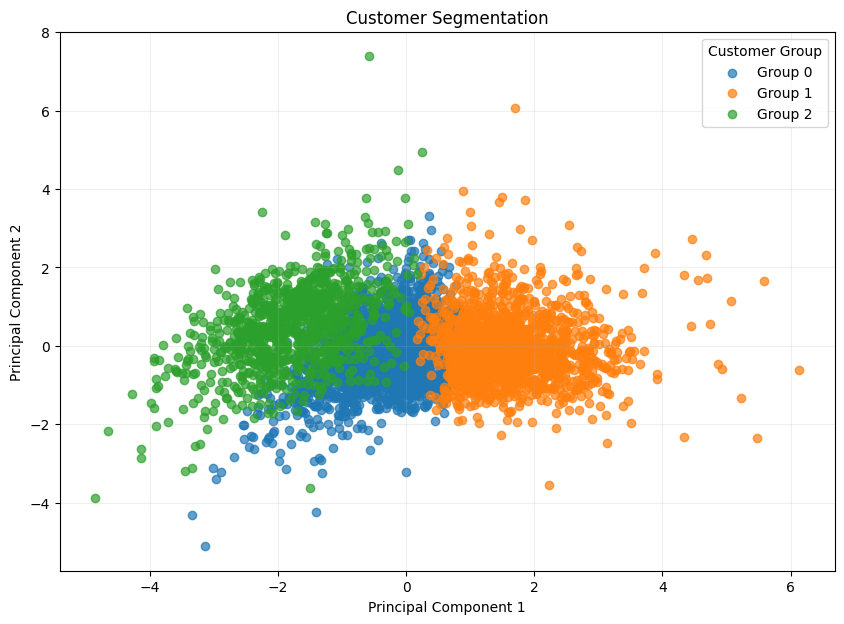

In [37]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

customer_df["PC1"] = X_pca[:, 0]
customer_df["PC2"] = X_pca[:, 1]



plt.figure(figsize=(10, 7))

for cluster in sorted(customer_df["cluster"].unique()):
    subset = customer_df[
        customer_df["cluster"] == cluster
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Group {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation")
plt.legend(title="Customer Group")
plt.grid(alpha=0.2)

plt.show()

In [38]:
# reference: https://www.geeksforgeeks.org/data-analysis/rfm-analysis-analysis-using-python/

rfm_df = customer_df[
    ["CustomerID", "recency", "frequency", "monetary"]
].copy()


rfm_df["R_rank"] = rfm_df["recency"].rank(ascending=False)
rfm_df["F_rank"] = rfm_df["frequency"].rank(ascending=True)
rfm_df["M_rank"] = rfm_df["monetary"].rank(ascending=True)

rfm_df["R_rank_norm"] = (
    rfm_df["R_rank"] / rfm_df["R_rank"].max()
) * 100

rfm_df["F_rank_norm"] = (
    rfm_df["F_rank"] / rfm_df["F_rank"].max()
) * 100

rfm_df["M_rank_norm"] = (
    rfm_df["M_rank"] / rfm_df["M_rank"].max()
) * 100

rfm_df["RFM_score"] = (
    0.15 * rfm_df["R_rank_norm"]
    + 0.28 * rfm_df["F_rank_norm"]
    + 0.57 * rfm_df["M_rank_norm"]
)

rfm_df["RFM_score"] *= 0.05

rfm_df["RFM_score"] = rfm_df["RFM_score"].round(2)

In [39]:
rfm_feature = [
    "R_rank_norm",
    "F_rank_norm",
    "M_rank_norm"
]

In [40]:
scaler = StandardScaler()
X = rfm_df[rfm_feature]
X_scaled = scaler.fit_transform(X)

X_scaled.shape

(4338, 3)

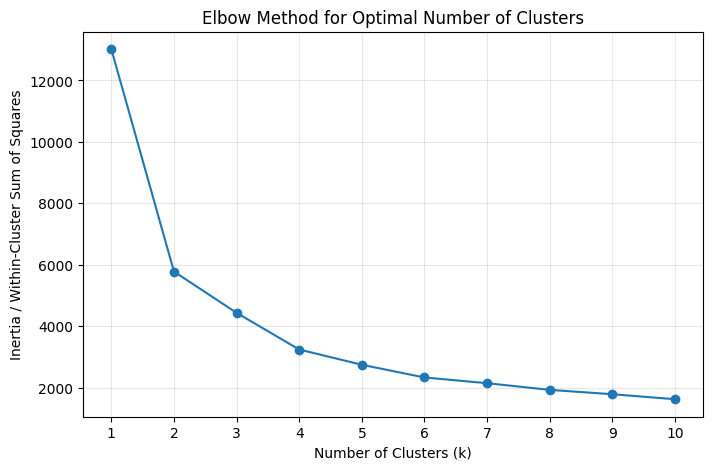

In [41]:
inertia = []
k_values = range(1, 11)
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [42]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init="auto"
)

rfm_df["cluster"] = kmeans.fit_predict(X_scaled)

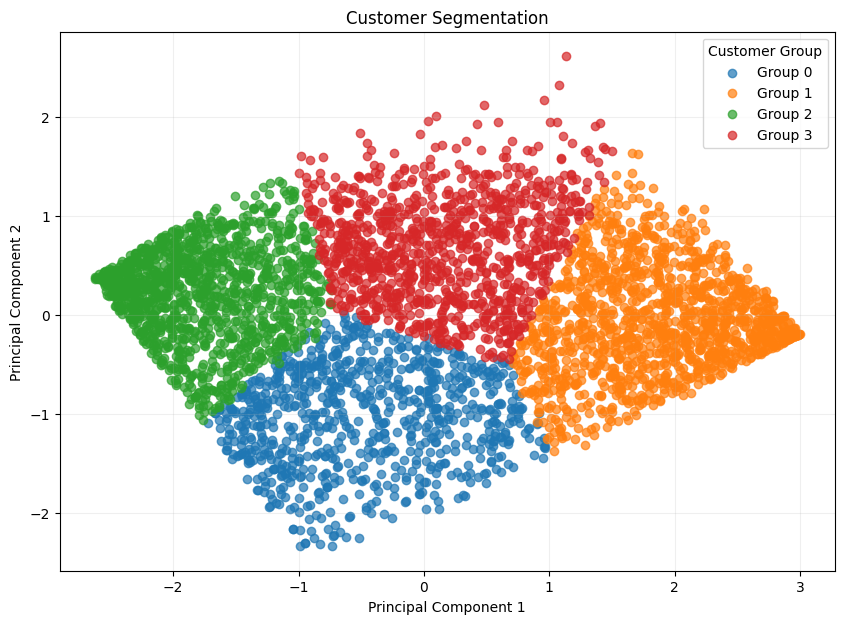

In [43]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

rfm_df["PC1"] = X_pca[:, 0]
rfm_df["PC2"] = X_pca[:, 1]



plt.figure(figsize=(10, 7))

for cluster in sorted(rfm_df["cluster"].unique()):
    subset = rfm_df[
        rfm_df["cluster"] == cluster
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Group {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation")
plt.legend(title="Customer Group")
plt.grid(alpha=0.2)

plt.show()

In [44]:
rfm_df.sort_values(by='RFM_score', ascending=False)

,CustomerID,recency,frequency,monetary,R_rank,F_rank,M_rank,R_rank_norm,F_rank_norm,M_rank_norm,RFM_score,cluster,PC1,PC2
1879,14911.0,1,201,143711.17,4292.0,4337.0,4334.0,100.000000,99.976948,99.907792,5.00,1,2.996402,-0.190390
4201,18102.0,1,60,259657.30,4292.0,4328.0,4337.0,100.000000,99.769479,99.976948,5.00,1,2.993274,-0.191274
2176,15311.0,1,91,60632.75,4292.0,4333.0,4325.0,100.000000,99.884740,99.700323,4.99,1,2.990078,-0.194507
326,12748.0,1,209,33053.19,4292.0,4338.0,4310.0,100.000000,100.000000,99.354541,4.98,1,2.985449,-0.198821
1689,14646.0,2,73,280206.02,4202.5,4331.0,4338.0,97.914725,99.838635,100.000000,4.98,1,2.958806,-0.129385
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1815,14821.0,367,1,48.80,54.5,747.0,37.0,1.269804,17.219917,0.852928,0.27,2,-2.600610,0.359455
1650,14589.0,372,1,39.75,33.0,747.0,29.0,0.768872,17.219917,0.668511,0.27,2,-2.613190,0.371195
1640,14576.0,372,1,35.40,33.0,747.0,20.0,0.768872,17.219917,0.461042,0.26,2,-2.617487,0.367951
402,12855.0,373,1,38.10,17.0,747.0,25.0,0.396086,17.219917,0.576302,0.26,2,-2.621618,0.380636


In [45]:
category_range = rfm_df.groupby('cluster')['RFM_score'].agg(lambda x: x.max() - x.min())
category_range

cluster
0    2.89
1    2.23
2    2.03
3    2.68
Name: RFM_score, dtype: float64

In [46]:
rfm_df['cluster'].value_counts()

cluster
1    1283
2    1207
3    1018
0     830
Name: count, dtype: int64

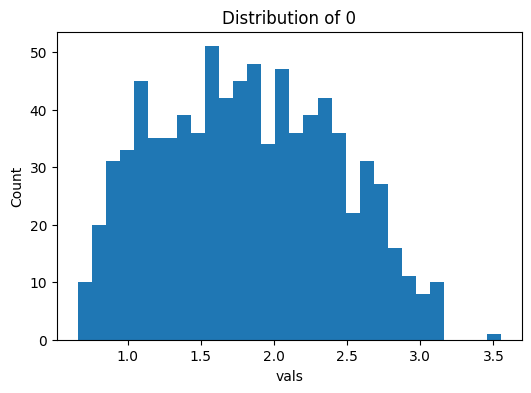

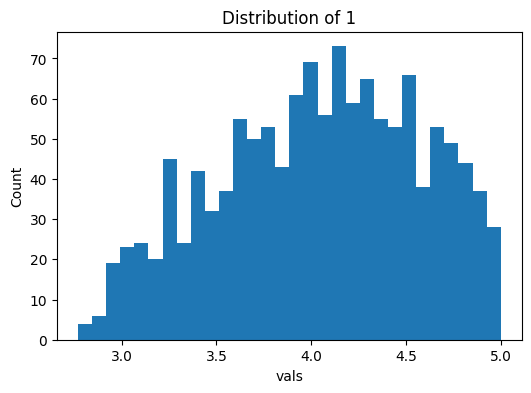

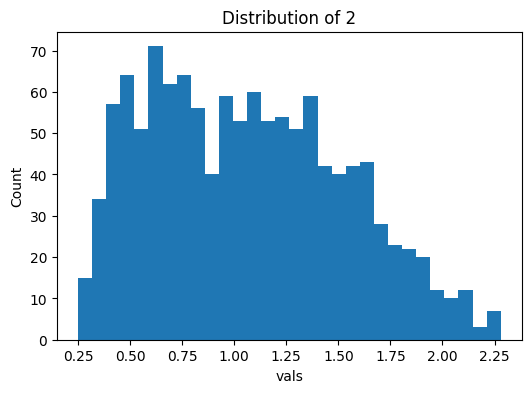

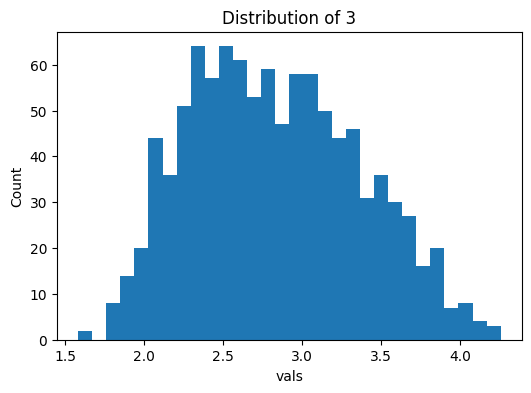

In [47]:
for i in range(0,4):
    cluster_info = rfm_df[rfm_df['cluster'] == i]
    plt.figure(figsize=(6, 4))
    plt.hist(cluster_info[f"RFM_score"], bins=30)
    plt.title(f"Distribution of {i}")
    plt.xlabel("vals")
    plt.ylabel("Count")
    plt.show()

In [48]:
rfm_df

,CustomerID,recency,frequency,monetary,R_rank,F_rank,M_rank,R_rank_norm,F_rank_norm,M_rank_norm,RFM_score,cluster,PC1,PC2
0,12346.0,326,1,77183.60,161.0,747.0,4329.0,3.751165,17.219917,99.792531,3.11,3,-0.507979,1.833806
1,12347.0,2,7,4310.00,4202.5,3710.0,4004.0,97.914725,85.523283,92.300599,4.56,1,2.484704,-0.385319
2,12348.0,75,4,1797.24,1653.0,3030.5,3335.0,38.513514,69.859382,76.878746,3.46,3,0.782264,0.959285
3,12349.0,19,1,1757.55,3182.0,747.0,3312.0,74.137931,17.219917,76.348548,2.97,0,0.237304,-0.587438
4,12350.0,310,1,334.40,230.5,747.0,1242.0,5.370457,17.219917,28.630705,1.10,2,-1.953568,0.674017
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4333,18280.0,278,1,180.60,353.0,747.0,571.0,8.224604,17.219917,13.162748,0.68,2,-2.224030,0.348878
4334,18281.0,181,1,80.82,859.5,747.0,104.0,20.025629,17.219917,2.397418,0.46,2,-2.240637,-0.163919
4335,18282.0,8,2,178.05,3794.5,1911.0,551.0,88.408667,44.052559,12.701706,1.64,0,-0.241653,-1.744960
4336,18283.0,4,16,2045.53,4015.0,4182.0,3465.0,93.546132,96.403873,79.875519,4.33,1,2.390102,-0.349003


In [51]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_df = (
    df.groupby("CustomerID")
      .agg(
          monetary=("Transaction_Total", "sum"),
          frequency=("InvoiceNo", "nunique"),
          total_quantity=("Quantity", "sum"),
          unique_products=("StockCode", "nunique"),
          last_purchase=("InvoiceDate", "max")
      )
      .reset_index()
)

customer_df = customer_df[['CustomerID', 'total_quantity', 'unique_products', 'last_purchase']]
customer_df

,CustomerID,total_quantity,unique_products,last_purchase
0,12346.0,74215,1,2011-01-18 10:01:00
1,12347.0,2458,103,2011-12-07 15:52:00
2,12348.0,2341,22,2011-09-25 13:13:00
3,12349.0,631,73,2011-11-21 09:51:00
4,12350.0,197,17,2011-02-02 16:01:00
...,...,...,...,...
4333,18280.0,45,10,2011-03-07 09:52:00
4334,18281.0,54,7,2011-06-12 10:53:00
4335,18282.0,103,12,2011-12-02 11:43:00
4336,18283.0,1357,263,2011-12-06 12:02:00


In [55]:
import pandas as pd
comparison_data = pd.merge(rfm_df, customer_df, on='CustomerID')
comparison_data

,CustomerID,recency,frequency,monetary,R_rank,F_rank,M_rank,R_rank_norm,F_rank_norm,M_rank_norm,RFM_score,cluster,PC1,PC2,total_quantity,unique_products,last_purchase
0,12346.0,326,1,77183.60,161.0,747.0,4329.0,3.751165,17.219917,99.792531,3.11,3,-0.507979,1.833806,74215,1,2011-01-18 10:01:00
1,12347.0,2,7,4310.00,4202.5,3710.0,4004.0,97.914725,85.523283,92.300599,4.56,1,2.484704,-0.385319,2458,103,2011-12-07 15:52:00
2,12348.0,75,4,1797.24,1653.0,3030.5,3335.0,38.513514,69.859382,76.878746,3.46,3,0.782264,0.959285,2341,22,2011-09-25 13:13:00
3,12349.0,19,1,1757.55,3182.0,747.0,3312.0,74.137931,17.219917,76.348548,2.97,0,0.237304,-0.587438,631,73,2011-11-21 09:51:00
4,12350.0,310,1,334.40,230.5,747.0,1242.0,5.370457,17.219917,28.630705,1.10,2,-1.953568,0.674017,197,17,2011-02-02 16:01:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4333,18280.0,278,1,180.60,353.0,747.0,571.0,8.224604,17.219917,13.162748,0.68,2,-2.224030,0.348878,45,10,2011-03-07 09:52:00
4334,18281.0,181,1,80.82,859.5,747.0,104.0,20.025629,17.219917,2.397418,0.46,2,-2.240637,-0.163919,54,7,2011-06-12 10:53:00
4335,18282.0,8,2,178.05,3794.5,1911.0,551.0,88.408667,44.052559,12.701706,1.64,0,-0.241653,-1.744960,103,12,2011-12-02 11:43:00
4336,18283.0,4,16,2045.53,4015.0,4182.0,3465.0,93.546132,96.403873,79.875519,4.33,1,2.390102,-0.349003,1357,263,2011-12-06 12:02:00


In [56]:
cluster = comparison_data[comparison_data['cluster'] == 0]
cluster

,CustomerID,recency,frequency,monetary,R_rank,F_rank,M_rank,R_rank_norm,F_rank_norm,M_rank_norm,RFM_score,cluster,PC1,PC2,total_quantity,unique_products,last_purchase
3,12349.0,19,1,1757.55,3182.0,747.0,3312.0,74.137931,17.219917,76.348548,2.97,0,0.237304,-0.587438,631,73,2011-11-21 09:51:00
19,12367.0,4,1,168.90,4015.0,747.0,509.0,93.546132,17.219917,11.733518,1.28,0,-0.761612,-2.164170,173,11,2011-12-05 16:48:00
24,12374.0,25,1,742.93,2899.0,747.0,2319.0,67.544268,17.219917,53.457815,2.27,0,-0.352113,-0.752822,342,33,2011-11-14 15:37:00
25,12375.0,11,2,457.50,3579.5,1911.0,1658.0,83.399348,44.052559,38.220378,2.33,0,0.199292,-1.199779,178,14,2011-11-29 10:36:00
32,12384.0,29,2,585.27,2759.5,1911.0,1961.0,64.294035,44.052559,45.205164,2.39,0,0.009866,-0.532859,126,26,2011-11-11 08:39:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4326,18270.0,38,2,283.15,2460.5,1911.0,979.0,57.327586,44.052559,22.568004,1.69,0,-0.580818,-0.683396,101,11,2011-11-01 13:57:00
4328,18273.0,2,3,204.00,4202.5,2582.5,677.5,97.914725,59.532042,15.617796,2.01,0,0.325196,-1.830284,80,1,2011-12-07 13:16:00
4329,18274.0,30,1,175.92,2711.0,747.0,542.0,63.164026,17.219917,12.494237,1.07,0,-1.277149,-1.265364,88,11,2011-11-09 17:03:00
4330,18276.0,44,1,335.86,2316.0,747.0,1250.0,53.960857,17.219917,28.815122,1.47,0,-1.100047,-0.741550,186,14,2011-10-27 10:54:00
